In [1]:

import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp

import matplotlib.pyplot as plt
try:
    import cmasher as cmr
    CMAP = cmr.sunburst_r
    RESID_CMAP = cmr.fusion
except ImportError:
    CMAP = "viridis"
    RESID_CMAP = "RdBu_r"

from numpyro.infer.autoguide import AutoNormal

from stream_membership.plot import plot_data_projections

import pickle
from pathlib import Path
import sys

import traceback

/Users/Tavangar/Work/virtual_envs/.stream-env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/Tavangar/Work/virtual_envs/.stream-env/lib/python3.12/site-packages/jax_cosmo/__init__.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound


In [2]:

# Locate the gd1-dr3 repo root so this notebook works both from a checkout at
# the hardcoded path used elsewhere in this repo (your machine) and from a
# differently-located clone / sandbox mount (e.g. this notebook's own parent
# directory).
_CANDIDATE_ROOTS = [
    Path("/Users/Tavangar/Work/gd1-dr3"),
    Path.cwd().parent,
    Path.cwd(),
]
ROOT_DIR = next((p for p in _CANDIDATE_ROOTS if (p / "data").exists() and (p / "scripts").exists()), _CANDIDATE_ROOTS[0])
DATA_DIR = ROOT_DIR / "data"
SCRIPTS_DIR = ROOT_DIR / "scripts"

sys.path.append(str(SCRIPTS_DIR))

import initialize_stream as init_stream
import pretrain_bkg_cmd_flow as cmd_flow_pretrain
from svi_helpers import *

print(f"ROOT_DIR = {ROOT_DIR}")

ROOT_DIR = /Users/Tavangar/Work/gd1-dr3


In [3]:

STREAM_NAME = "GD-1"
PHI1_LIM = [-100, 20]

# Matches scripts/run_full_gd1_model.py's CLI defaults.
NUM_STEPS = dict(bkg=10_000, stream=20_000, bkg_stream=7_500, full=20_000)
PROXY_MAX_N = None
BKG_KNOT_SPACINGS = jnp.array([40, 40, 40, 40, 40])       # phi1, phi2, pm1, pm2, rv
STREAM_KNOT_SPACINGS = jnp.array([5, 10, 10, 10, 10])  # phi1, phi2, pm1, pm2, rv
N_MIXTURE = 2  # number of mixture components in the background pm1/pm2/rv models

OFFTRACK_DX = jnp.array([3, 1])  # [phi1, phi2] spacing (degrees)

# Cache fitted SVI results here, keyed by knot spacing (see each stage below),
# so rerunning the notebook picks up existing fits instead of refitting from
# scratch. Smoke-test runs are cached in a separate subdirectory so they can
# never collide with (or clutter) real production results.
SVI_RESULTS_DIR = ROOT_DIR / "svi_results"
SVI_RESULTS_DIR = SVI_RESULTS_DIR / "flow_test"
SVI_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"NUM_STEPS = {NUM_STEPS}")
print(f"SVI_RESULTS_DIR = {SVI_RESULTS_DIR}")

NUM_STEPS = {'bkg': 10000, 'stream': 20000, 'bkg_stream': 7500, 'full': 20000}
SVI_RESULTS_DIR = /Users/Tavangar/Work/gd1-dr3/svi_results/flow_test


In [4]:
run_data_, bkg_data_, stream_data_, pawprint = load_real_data()

print(f"bkg_data: {len(bkg_data_)} rows")

bkg_data, bkg_data_err = table_to_arrays(bkg_data_)
run_data, run_data_err = table_to_arrays(run_data_)
stream_data, stream_data_err = table_to_arrays(stream_data_)

coord_bounds, plot_grids = get_coord_bounds(bkg_data, pawprint)
phi1_lim = coord_bounds["phi1"]

PyMultiNest not imported.  MultiNest fits will not work.


Loaded cached CATS-processed data from /Users/Tavangar/Work/gd1-dr3/data/post_cats_data_flow_version.pkl
bkg_data: 382561 rows


In [5]:
CMD_FLOW_PREFIX = DATA_DIR / "bkg_cmd_flow"

flow_key = jax.random.key(42)

cmd_flow, cmd_norm_stats = cmd_flow_pretrain.load_flow(CMD_FLOW_PREFIX, flow_key)
print(f"Loaded pretrained CMD flow from {CMD_FLOW_PREFIX}.eqx")

Loaded pretrained CMD flow from /Users/Tavangar/Work/gd1-dr3/data/bkg_cmd_flow.eqx


In [12]:
import importlib
importlib.reload(sys.modules['initialize_stream'])
importlib.reload(sys.modules['svi_helpers'])
import initialize_stream as init_stream
from svi_helpers import *

In [24]:
coords = ['phi1', 'phi2']

BKG_KNOT_SPACINGS = jnp.array([20, 40, 40, 40, 40])

bkg_model = init_stream.make_bkg_model_component(coords, 
    knot_spacings=BKG_KNOT_SPACINGS, n_mixture=N_MIXTURE,
    coord_bounds=coord_bounds, data=bkg_data, stream_data=stream_data, 
    # cmd_flow=cmd_flow, cmd_norm_stats=cmd_norm_stats
)


n_phi1_knots = bkg_model.coord_parameters["phi1"]["locs"].shape[-1]
n_phi2_knots = bkg_model.coord_parameters["phi2"]["knots"].shape[-1]

bkg_init_params = {
    "phi1": {
        "mixing_distribution": jnp.ones(n_phi1_knots) / n_phi1_knots,
        "scales": jnp.full(n_phi1_knots, BKG_KNOT_SPACINGS[0]),
    },
    "phi2": {
        "a_vals": jnp.full(n_phi2_knots, 0),
    },
}

keys = jax.random.split(jax.random.PRNGKey(42), num=2)

In [29]:
try:
    bkg_svi_results, bkg_guide = run_SVI(
        bkg_model, bkg_init_params, bkg_data, bkg_data_err,
        num_steps=2000, GuideFunction=AutoNormal, keys=keys,
        init_lr=1e-1, adaptive_lr=True, num_particles=3,
    )
except Exception:
    traceback.print_exc()
# save_svi_result(bkg_filename, bkg_svi_results, bkg_guide)

bkg_params = get_svi_params(model=bkg_model, data=bkg_data, svi_results=bkg_svi_results, guide=bkg_guide)


100%|██████████| 2000/2000 [01:42<00:00, 19.57it/s, init loss: 3041366.0946, avg. loss [1901-2000]: 2618486.6788]


In [25]:
print("final ELBO loss:", bkg_svi_results.losses[-1])

final ELBO loss: 2618595.6612322824


In [27]:
bkg_params

{'phi1': {'mixing_distribution': Array([0.08309369, 0.11275273, 0.64634373, 0.00315055, 0.01175177,
         0.07833808, 0.06456945], dtype=float64),
  'scales': Array([13.55654442, 14.08424325, 37.62409416, 17.29755664,  5.67625836,
         10.2731198 ,  9.13266308], dtype=float64)},
 'phi2': {'a_vals': Array([0.13870652, 0.12958029, 0.04901341, 0.02020651], dtype=float64)}}

In [ ]:
with open('../../data/post_cats_data_flow_version.pkl', 'rb') as input_file_:
    post_cats = pickle.load(input_file_)
iso_obj = post_cats['iso_obj']

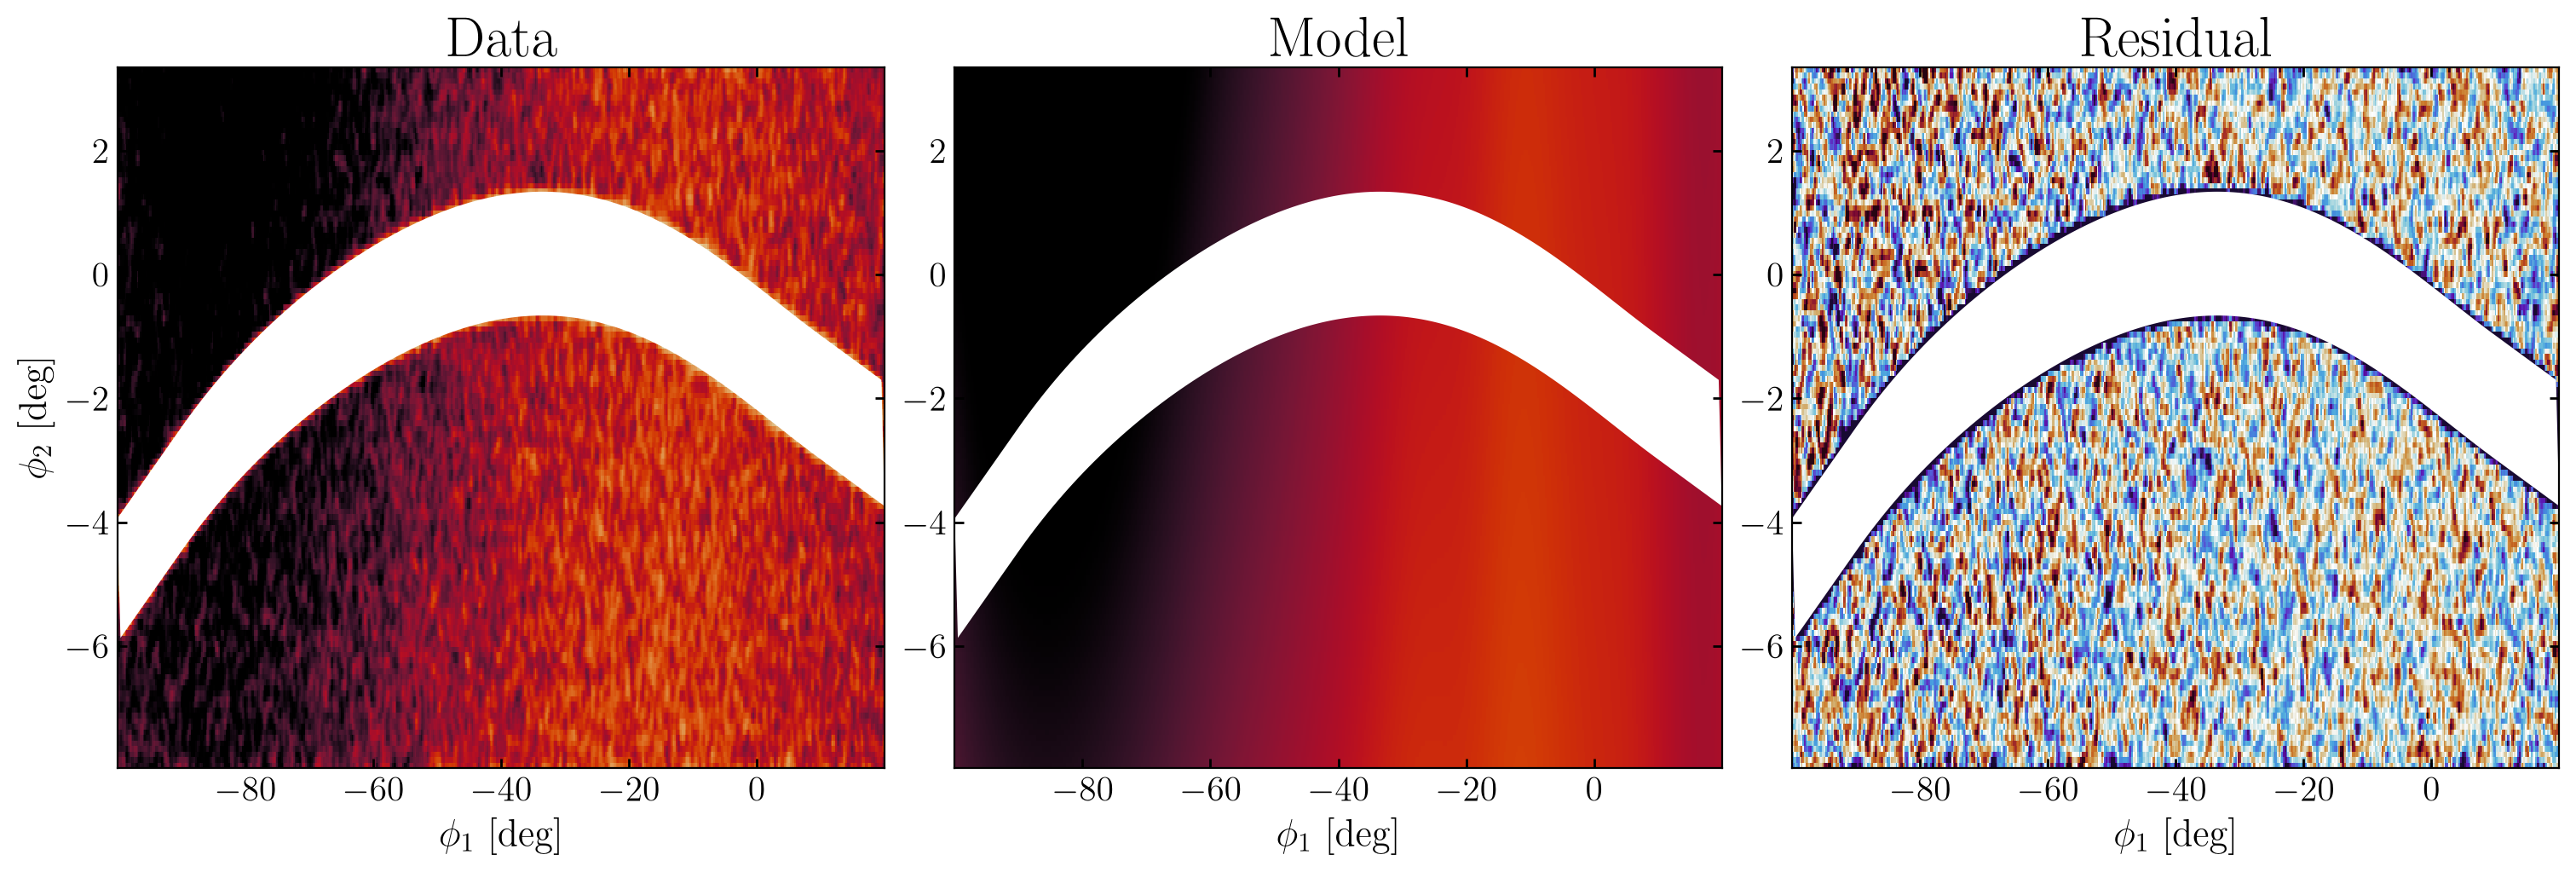

In [28]:
import matplotlib as mpl
import numpy as np
# Diagnostics: kinematic projections (data vs. model) + a CMD panel (data vs.
# flow samples at the same phi1 values), for a quick visual sanity check.
fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)

axes = np.atleast_2d(axes)
dat = plot_data_projections(
    data=bkg_data_,
    grids=plot_grids,
    axes=axes[0, 0],
    pcolormesh_kwargs=dict(rasterized=True, vmax=10, vmin=0, cmap=CMAP),
    coord_names=[('phi1', 'phi2')]
)

mod = bkg_model.plot_model_projections(ndata=len(bkg_data_), grids=plot_grids, grid_coord_names=[('phi1', 'phi2')],
                                 pars=bkg_params, axes=axes[0, 1], label=False,
                                 pcolormesh_kwargs=dict(rasterized=True, vmax=10, vmin=0, cmap=CMAP))

bkg_model.plot_residual_projections(
    grids=plot_grids, grid_coord_names=[('phi1', 'phi2')], 
    pars=bkg_params,
    data=bkg_data_, axes=axes[0, 2], label=False, 
    pcolormesh_kwargs=dict(vmin=-2, vmax=2, cmap=cmr.fusion, rasterized=True)
)

axes[0, 0].set_title('Data', fontsize=24)
axes[0, 1].set_title('Model', fontsize=24)
axes[0, 2].set_title('Residual', fontsize=24)


blank = cmr.take_cmap_colors(CMAP, N=2, return_fmt='hex')[0]
for ax in axes[0,:]:
    patch_sky = mpl.patches.Polygon(
            iso_obj.pawprint.skyprint["stream"].vertices[::50],
            facecolor=blank,
            alpha=1
        )
    ax.add_patch(patch_sky)

plt.show()

In [ ]:
bkg_filename = SVI_RESULTS_DIR / "bkg_{}_{}_{}_{}_auto_normal.pkl".format(*BKG_KNOT_SPACINGS)

bkg_model = init_stream.make_bkg_model_component(
    knot_spacings=BKG_KNOT_SPACINGS, n_mixture=N_MIXTURE,
    coord_bounds=coord_bounds, data=bkg_data,
    # cmd_flow=cmd_flow, cmd_norm_stats=cmd_norm_stats,
)

_d = None #try_load_cached(bkg_filename)
if _d is not None:
    print(f"Loaded cached background SVI result from {bkg_filename}")
    bkg_svi_results, bkg_guide = _d["svi_results"], _d["guide"]
else:
    n_phi1_knots = bkg_model.coord_parameters["phi1"]["locs"].shape[-1]
    n_phi2_knots = bkg_model.coord_parameters["phi2"]["knots"].shape[-1]
    n_pm1_knots = bkg_model.coord_parameters["pm1"]["knots"].shape[-1]
    n_pm2_knots = bkg_model.coord_parameters["pm2"]["knots"].shape[-1]
    n_rv_knots = bkg_model.coord_parameters["rv"]["knots"].shape[-1]

    bkg_init_params = {
        "phi1": {
            "mixing_distribution": jnp.ones(n_phi1_knots) / n_phi1_knots,
            "scales": jnp.full(n_phi1_knots, BKG_KNOT_SPACINGS[0]),
        },
        "phi2": {
            "mixing_distribution": jnp.ones(N_MIXTURE) / N_MIXTURE,
            "loc_vals": jnp.full((N_MIXTURE, n_phi2_knots), 4),
            "scale_vals": jnp.full((N_MIXTURE, n_phi2_knots), 10.0),
        },
        "pm1": {
            "mixing_distribution": jnp.ones(N_MIXTURE) / N_MIXTURE,
            "loc_vals": jnp.full((N_MIXTURE, n_pm1_knots), 0),
            "scale_vals": jnp.full((N_MIXTURE, n_pm1_knots), 5.0),
        },
        "pm2": {
            "mixing_distribution": jnp.ones(N_MIXTURE) / N_MIXTURE,
            "loc_vals": jnp.full((N_MIXTURE, n_pm2_knots), -3.0),
            "scale_vals": jnp.full((N_MIXTURE, n_pm2_knots), 3.0),
        },
        "rv": {
            "mixing_distribution": jnp.ones(N_MIXTURE) / N_MIXTURE,
            "loc_vals": jnp.full((N_MIXTURE, n_rv_knots), -100),
            "scale_vals": jnp.full((N_MIXTURE, n_rv_knots), 50),
        },
        # No entry needed for the CMD term -- `flow`/`norm_stats` are bound
        # as fixed constructor args (see initialize_stream.make_bkg_model_component)
        # and "x" is passed through directly from coord_parameters, not sampled.
    }

    print(f"Fitting background model ({NUM_STEPS['bkg']} SVI steps)...")
    keys = jax.random.split(jax.random.PRNGKey(42), num=2)

TypeError: make_bkg_model_component() missing 1 required positional argument: 'coords'

In [ ]:
# from debug_svi_step1_nan import debug_svi_step1_nan
# debug_svi_step1_nan(bkg_model, bkg_init_params, bkg_data, bkg_data_err,
#                         num_particles=3, init_lr=1e-2)

try:
    bkg_svi_results, bkg_guide = run_SVI(
        bkg_model, bkg_init_params, bkg_data, bkg_data_err,
        num_steps=NUM_STEPS["bkg"], GuideFunction=AutoNormal, keys=keys,
        init_lr=1e-2, adaptive_lr=True, num_particles=3,
    )
except Exception:
    traceback.print_exc()
save_svi_result(bkg_filename, bkg_svi_results, bkg_guide)

bkg_params = get_svi_params(model=bkg_model, data=bkg_data, svi_results=bkg_svi_results, guide=bkg_guide)
print("final ELBO loss:", bkg_svi_results.losses[-1])